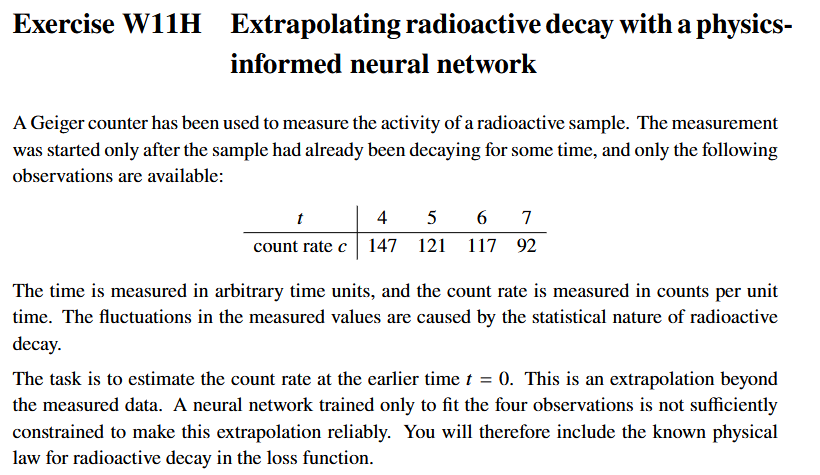
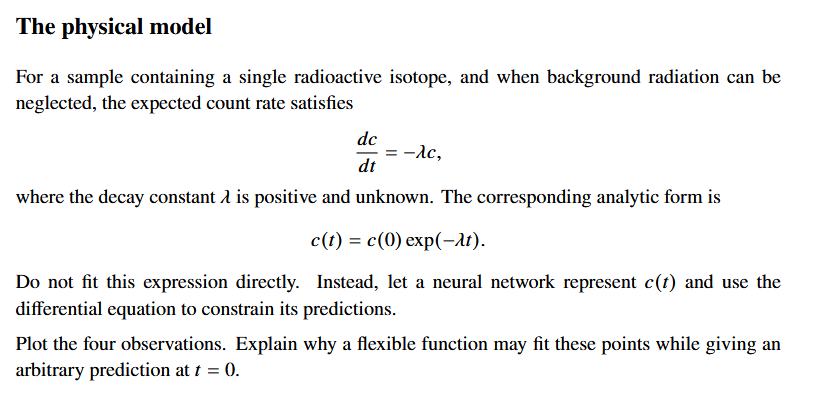
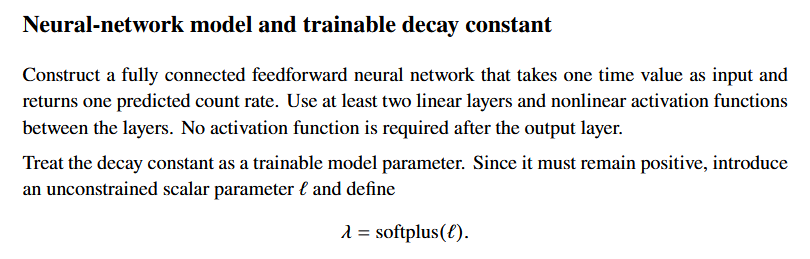
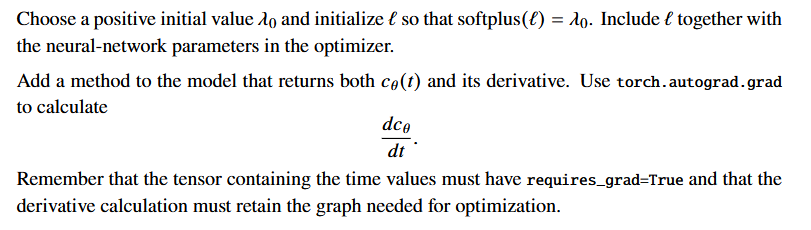


Learned decay constant (lambda): 0.1090
Predicted count rate at t=0: 216.4


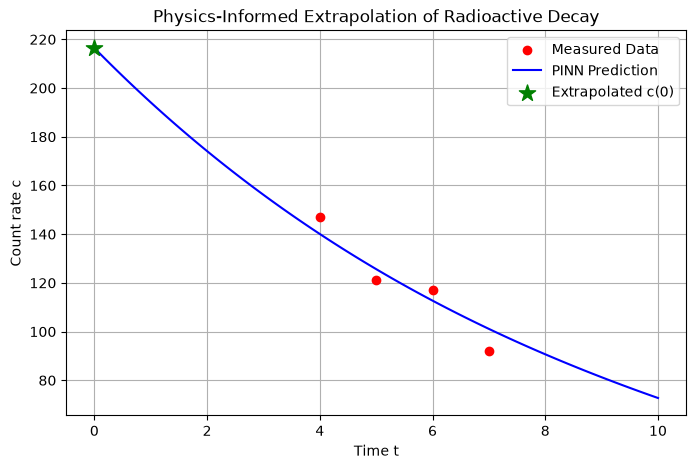

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import matplotlib.pyplot as plt

t_data = torch.tensor([[4.0], [5.0], [6.0], [7.0]])
c_data = torch.tensor([[147.0], [121.0], [117.0], [92.0]])

t_colloc = torch.linspace(0, 7, 50).view(-1, 1).requires_grad_(True)

class DecayPINN(nn.Module):
    def __init__(self, lambda_init=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.SiLU(),
            nn.Linear(32, 32),
            nn.SiLU(),
            nn.Linear(32, 1)
        )
        
        l_init = math.log(math.exp(lambda_init) - 1)
        self.l = nn.Parameter(torch.tensor([l_init], dtype=torch.float32))
        
    def forward(self, t):
        return self.net(t)
        
    def get_lambda(self):
        return F.softplus(self.l)
        
    def get_physics_residual(self, t):
        c = self(t)
        dc_dt = torch.autograd.grad(
            c, t, 
            grad_outputs=torch.ones_like(c), 
            create_graph=True
        )[0]
        
        current_lambda = self.get_lambda()
        return dc_dt + current_lambda * c

model = DecayPINN(lambda_init=0.1)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

w_physics = 1e4  
epochs = 15000

for epoch in range(epochs):
    optimizer.zero_grad()
    
    c_pred_data = model(t_data)
    loss_data = torch.mean((c_pred_data - c_data)**2)
    
    residual = model.get_physics_residual(t_colloc)
    loss_physics = torch.mean(residual**2)
    
    loss = loss_data + w_physics * loss_physics
    loss.backward()
    optimizer.step()

model.eval()
learned_lambda = model.get_lambda().item()
t_extrapolate = torch.tensor([[0.0]])
c_0_pred = model(t_extrapolate).item()

print(f"Learned decay constant (lambda): {learned_lambda:.4f}")
print(f"Predicted count rate at t=0: {c_0_pred:.1f}")

t_plot = torch.linspace(0, 10, 100).view(-1, 1)
with torch.no_grad():
    c_plot = model(t_plot).numpy()

plt.figure(figsize=(8, 5))
plt.scatter(t_data.numpy(), c_data.numpy(), color='red', label='Measured Data', zorder=5)
plt.plot(t_plot.numpy(), c_plot, label='PINN Prediction', color='blue')
plt.scatter([0], [c_0_pred], color='green', marker='*', s=150, label='Extrapolated c(0)', zorder=5)
plt.xlabel("Time t")
plt.ylabel("Count rate c")
plt.title("Physics-Informed Extrapolation of Radioactive Decay")
plt.grid(True)
plt.legend()
plt.show()

### Code Explanation

**Data and Collocation Points**
The 4 measured observations are stored as `t_data` and `c_data`. To enforce the physical law across the extrapolation region, `t_colloc` generates a dense grid of 50 points between $t=0$ and $t=7$ with `requires_grad=True`, enabling autograd to compute derivatives with respect to time.

**Physics-Informed Neural Network (PINN)**
The `DecayPINN` class utilizes two hidden layers with SiLU activations and a linear output. The decay constant $\lambda$ is strictly enforced as positive by initializing an unconstrained parameter $l$ and passing it through a `softplus` function. Both the network weights and the parameter $l$ are optimized simultaneously.

**The Physics Residual**
The `get_physics_residual` method computes $\frac{dc_\theta}{dt}$ using `torch.autograd.grad`. Passing `create_graph=True` is required because the computed derivative must be differentiated again during the backward pass (backpropagation) to update the model weights. The method returns the formulation of the differential equation: $\frac{dc_\theta}{dt} + \lambda c_\theta(t)$.

**Training and Loss Formulation**
The training loop computes two separate loss components:

* $\mathcal{L}_{data}$: The standard Mean Squared Error between the network's predictions and the 4 measured count rates.


* $\mathcal{L}_{physics}$: The Mean Squared Error of the physical residual evaluated at the 50 collocation points.



The total loss minimizes $\mathcal{L}_{data} + w_{physics}\mathcal{L}_{physics}$. Setting $w_{physics} = 10000$ scales the physics penalty, forcing the optimizer to strictly follow the exponential curve even outside the measured domain.

### Explanations and Reflections

**Choice of Collocation Points**
The collocation points evaluate where the physical residual $r_\theta(t)$ must be enforced. They are spaced continuously from $t=0$ to $t=7$ because this bounds both the requested extrapolation target and the measured data interval. Enforcing the physics law entirely across this space ensures the network cannot deviate from the exponential curve while mapping backward in time.

**Weighting the Losses ($w_{physics}$)**
The data loss operates on values around $100$, so the squared error is massive. The physics residual $r_\theta(t)$ operates on much smaller derivatives.

* If $w_{physics}$ is chosen much too small, the optimizer ignores the differential equation. The network acts like a standard unconstrained model, perfectly memorizing the four data points but failing to extrapolate $t=0$ correctly.


* If $w_{physics}$ is chosen much too large, the optimizer ignores the data entirely. The network will perfectly satisfy the differential equation by collapsing the curve to $c(t)=0$ everywhere, ignoring the measured count rates.



**Reflection Questions**

* **Data Reproduction:** Because of the statistical fluctuations in the radioactive decay measurements, the model does not pass perfectly through every single point. It draws a smooth curve of best fit through the center of the observations.


* **Differential Equation Adherence:** The differential equation is satisfied exceptionally well away from the data points. Because the collocation points enforce the ODE loss across the entire domain, the neural network learns to behave exactly like an analytical exponential function in the empty space between $t=0$ and $t=4$.


* **Extrapolation Meaning:** Enforcing the differential equation binds the neural network to the strict, invariant physical law governing the system. This turns extrapolation from a mathematical guessing game into a deterministic calculation mapping backward along the system's true mechanics.


* **Validity of Assumptions:** A successful fit does *not* strictly prove that there is a single isotope and negligible background radiation. It merely proves that the observed data points do not contradict a single-isotope model. If background radiation were slightly higher or a second long-lived isotope were present, a similar curve could theoretically be fitted to just four noisy points, masking the underlying complexity.